# IT25100429 — Member 5: EBM individual contribution

This notebook implements and compares six EBM varieties, documents tuning and a standardization sensitivity experiment, and supplies evidence for the individual assessment. Historical default-only outputs remain separate. No final holdout evaluation or group winner selection is performed.

## Model suitability
`Resigned` is binary and the data contain four nominal and thirteen numerical/ordinal predictors. InterpretML's ExplainableBoostingClassifier handles these types directly and learns nonlinear additive feature effects plus optional interactions. It is suitable for examining predictive associations while retaining readable explanations. A feature effect is not a causal reason for resignation. Approximately 10% positive prevalence makes raw accuracy inadequate.

## Implementation and parameters
The helper uses pandas, NumPy, scikit-learn and InterpretML. `fit` trains, `predict_proba` returns positive-class probabilities, `train_test_split` creates inner validation, and `StandardScaler` fits only on the appropriate training subset. All 17 shared predictors remain present; categorical fields use native nominal types.

Learning rate controls update size; maximum leaves controls tree complexity; minimum samples per leaf regularizes partitions; interactions controls pairwise terms. Fixed settings: 256 main-effect bins, 32 interaction bins, 5,000 maximum rounds, 100 early-stopping rounds, 15% internal validation, eight outer bags, seed 42, two workers. EBM's internal early stopping optimizes log loss; candidate selection uses external inner Average Precision. Internal EBM bagging is distinct from the project's five outer CV folds.

## Bounded manual grid and preprocessing
Three parameter settings are each trained with raw and standardized numerical values: six varieties. E01: learning rate .015, two leaves, minimum leaf size 10, no interactions. E02: .03, two leaves, minimum leaf size 4, five interactions. E03: .005, three leaves, minimum leaf size 2, ten interactions.

Scaling tests the standardization contribution without assuming a benefit: bin-based EBM commonly changes little under linear rescaling. Nominal fields are never standardized. Primary nested selection considers the three raw variants, as required by the shared feature representation; scaled variants are a separate sensitivity comparison.

## Validation and tuning boundaries
For each saved outer fold, the other 64,000 development records are split into 54,400 inner-training and 9,600 inner-validation records. Six candidates are fitted and measured on inner validation, then separately refitted on outer training and evaluated on the 16,000 outer-validation records. Primary selection uses inner AP only. Candidates within a predeclared .001 absolute AP of the best are treated as practically equivalent; fewer interactions, fewer leaves and stable candidate ID break ties. This margin is a decision rule, not a statistical significance test.

The experiment performs 30 inner fits and 30 outer refits. Each fixed variety and the nested selection procedure receive 80,000 OOF predictions. Fixed-variety comparisons are descriptive; choosing a winner by their outer scores would introduce selection optimism. The nested procedure supplies the primary evaluation. Final global refit and holdout remain reserved until group comparison and freeze.


## Individual preprocessing and parameter comparison

This notebook's full five-fold experiment compared three parameter settings as raw and fold-standardized numerical inputs. E01 has zero interactions and two leaves; E02 has five interactions and four leaves; E03 has ten interactions and two leaves. The table describes the **fixed-candidate** comparisons, separate from the formal inner-selected raw OOF result (pooled AP 0.099000).

| Candidate | Raw-input pooled AP | Standardized-input pooled AP |
|---|---:|---:|
| E01 | 0.098714 | 0.098714 |
| E02 | 0.097735 | 0.097735 |
| E03 | 0.098626 | 0.098626 |

Standardization changed none of the saved paired OOF probabilities. Outer scores were not used to select the formal candidate. See [Individual model evidence](../../../../reports/INDIVIDUAL_MODEL_EVIDENCE.md) for all metrics, validation and conclusions.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
from IPython.display import display
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/feature_contract.yaml").exists())
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
from src.models.ebm_experiments import CANDIDATES, run_experiments
pd.set_option("display.max_columns", None)
display(pd.DataFrame(CANDIDATES))

,setting,learning_rate,max_leaves,min_samples_leaf,interactions,preprocessing,candidate_id
0,E01,0.015,2,10,0,raw,E01_raw
1,E01,0.015,2,10,0,standardized,E01_standardized
2,E02,0.030,2,4,5,raw,E02_raw
3,E02,0.030,2,4,5,standardized,E02_standardized
4,E03,0.005,3,2,10,raw,E03_raw
5,E03,0.005,3,2,10,standardized,E03_standardized


## Evaluation metrics
Average Precision summarizes precision and recall across thresholds and is the primary metric for the minority class (chance reference approximately .1001). ROC-AUC measures ranking across both classes (chance .5). Brier score measures squared probability error (lower is better). Precision, recall, F1 and balanced accuracy describe decisions at .50; accuracy is shown to expose the majority-class trap. Fold means and standard deviations show variation but are not confidence intervals. AP is not trapezoidal PR-curve area.

## Run the experiments
This cell retrains all six varieties. The helper verifies dataset and registry hashes, reads only holdout identifiers for row exclusion, and prevents holdout predictors/labels from entering development training or scoring.

In [2]:
data, comparison, oof, metrics, output_dir = run_experiments(PROJECT_ROOT)
display(comparison)
display(pd.DataFrame([metrics]))

,setting,learning_rate,max_leaves,min_samples_leaf,interactions,preprocessing,candidate_id,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,cv_mean_ap,cv_std_ap
0,E01,0.015,2,10,0,raw,E01_raw,0.098714,0.495909,0.0,0.0,0.0,0.5,0.8999,0.090093,71992,0,8008,0,0,0.0,0.099570,0.002101
1,E01,0.015,2,10,0,standardized,E01_standardized,0.098714,0.495909,0.0,0.0,0.0,0.5,0.8999,0.090093,71992,0,8008,0,0,0.0,0.099570,0.002101
2,E02,0.030,2,4,5,raw,E02_raw,0.097735,0.492520,0.0,0.0,0.0,0.5,0.8999,0.090129,71992,0,8008,0,0,0.0,0.097884,0.002106
3,E02,0.030,2,4,5,standardized,E02_standardized,0.097735,0.492520,0.0,0.0,0.0,0.5,0.8999,0.090129,71992,0,8008,0,0,0.0,0.097884,0.002106
4,E03,0.005,3,2,10,raw,E03_raw,0.098626,0.494396,0.0,0.0,0.0,0.5,0.8999,0.090120,71992,0,8008,0,0,0.0,0.099097,0.001271
5,E03,0.005,3,2,10,standardized,E03_standardized,0.098626,0.494396,0.0,0.0,0.0,0.5,0.8999,0.090120,71992,0,8008,0,0,0.0,0.099097,0.001271


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,cv_mean_ap,cv_std_ap
0,0.099,0.495976,0.0,0.0,0.0,0.5,0.8999,0.090109,71992,0,8008,0,0,0.0,0.099558,0.002073


## Compare parameter varieties and standardization

preprocessing,raw,standardized,scaled_minus_raw_ap
setting,,,
E01,0.098714,0.098714,0.0
E02,0.097735,0.097735,0.0
E03,0.098626,0.098626,0.0


,setting,learning_rate,max_leaves,min_samples_leaf,interactions,preprocessing,candidate_id,outer_fold,inner_ap,inner_train_rows,inner_validation_rows
0,E01,0.015,2,10,0,raw,E01_raw,1,0.102646,54400,9600
1,E01,0.015,2,10,0,standardized,E01_standardized,1,0.102646,54400,9600
2,E02,0.030,2,4,5,raw,E02_raw,1,0.103665,54400,9600
3,E02,0.030,2,4,5,standardized,E02_standardized,1,0.103665,54400,9600
4,E03,0.005,3,2,10,raw,E03_raw,1,0.101975,54400,9600
5,E03,0.005,3,2,10,standardized,E03_standardized,1,0.101975,54400,9600
6,E01,0.015,2,10,0,raw,E01_raw,2,0.096931,54400,9600
7,E01,0.015,2,10,0,standardized,E01_standardized,2,0.096931,54400,9600
8,E02,0.030,2,4,5,raw,E02_raw,2,0.100460,54400,9600
9,E02,0.030,2,4,5,standardized,E02_standardized,2,0.100460,54400,9600


,inner_selected_candidate
cv_fold,
1,E02_raw
2,E02_raw
3,E01_raw
4,E01_raw
5,E03_raw


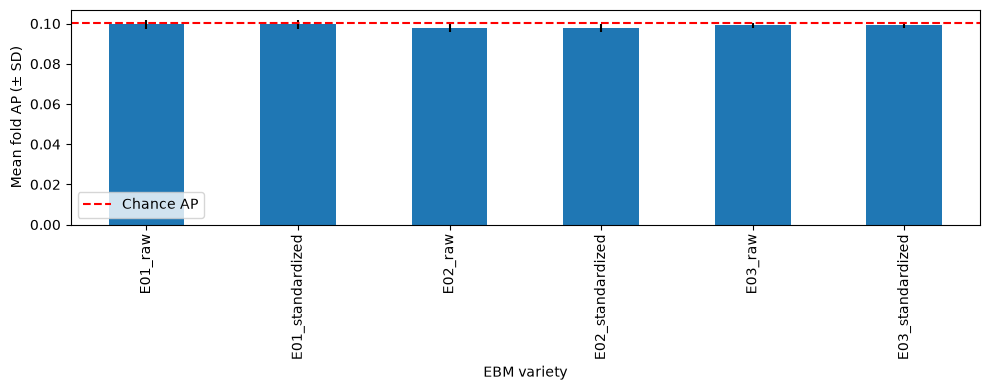

In [3]:
paired = comparison.pivot(index="setting", columns="preprocessing", values="average_precision")
paired["scaled_minus_raw_ap"] = paired["standardized"] - paired["raw"]
display(paired)
display(pd.read_csv(output_dir / "inner_selection.csv"))
display(oof.groupby("cv_fold").selected_candidate.first().rename("inner_selected_candidate").to_frame())
comparison.plot.bar(x="candidate_id", y="cv_mean_ap", yerr="cv_std_ap", legend=False, figsize=(10,4))
chance_line = plt.axhline(data.Resigned.mean(), color="red", linestyle="--", label="Chance AP")
plt.ylabel("Mean fold AP (± SD)"); plt.xlabel("EBM variety")
plt.legend(handles=[chance_line]); plt.tight_layout(); plt.savefig(output_dir / "candidate_comparison.png", dpi=160); plt.show()

## Primary nested evaluation and classification behavior

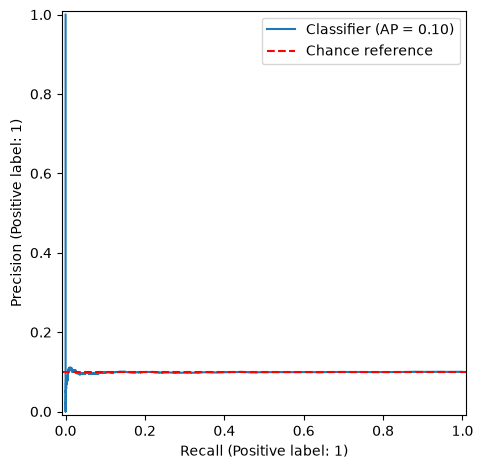

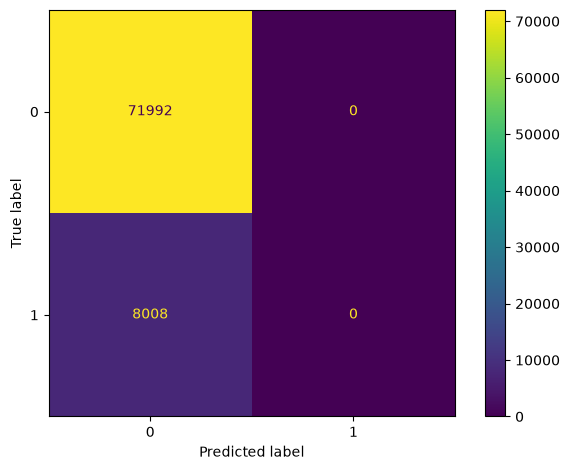

Nested AP=0.099000; ROC-AUC=0.495976; recall=0.000000; F1=0.000000
A majority-class model achieves about 90% accuracy while detecting no resignations. Interpret ranking and minority-class metrics first.


In [4]:
PrecisionRecallDisplay.from_predictions(oof.y_true, oof.y_probability)
plt.axhline(data.Resigned.mean(), color="red", linestyle="--", label="Chance reference")
plt.legend(); plt.tight_layout(); plt.savefig(output_dir / "nested_pr_curve.png", dpi=160); plt.show()
ConfusionMatrixDisplay.from_predictions(oof.y_true, (oof.y_probability >= .5).astype(int))
plt.tight_layout(); plt.savefig(output_dir / "nested_confusion_matrix.png", dpi=160); plt.show()
print(f"Nested AP={metrics['average_precision']:.6f}; ROC-AUC={metrics['roc_auc']:.6f}; recall={metrics['recall']:.6f}; F1={metrics['f1']:.6f}")
print("A majority-class model achieves about 90% accuracy while detecting no resignations. Interpret ranking and minority-class metrics first.")

## Conclusions and limitations
The following cell generates a conclusion from actual outputs. Small numerical differences should not be called meaningful improvements without additional uncertainty analysis. The bounded search does not exhaust all EBM configurations; a single inner split can produce unstable winners. Standardization may change rounding/binning while providing little predictive benefit. Internal log-loss early stopping differs from the AP selection criterion. The fixed .50 threshold can suppress minority-class predictions; threshold selection and calibration belong to later development-only evaluation. More useful improvements include repeated inner validation, probability calibration, carefully assessed class weighting and better longitudinal predictors. Any further experiment must preserve the frozen holdout boundary.

The dataset's observed feature regularities and near-chance historical results limit claims about real HR decisions. Importance graphs describe the fitted model even when predictive signal is weak. They do not establish causal effects or fairness.


In [5]:
lift = metrics["average_precision"] - data.Resigned.mean()
conclusion = (f"Primary nested EBM AP {metrics['average_precision']:.6f} (difference from prevalence {lift:+.6f}), "
              f"ROC-AUC {metrics['roc_auc']:.6f}, Brier {metrics['brier_score']:.6f}. "
              f"Largest absolute scaling AP difference across paired varieties: {paired.scaled_minus_raw_ap.abs().max():.6f}. "
              "These development results require comparison against chance references and fold variability; "
              "they do not establish deployment readiness. Six varieties were evaluated; final group model selection and holdout remain pending.")
print(conclusion)
(output_dir / "conclusion.txt").write_text(conclusion)

Primary nested EBM AP 0.099000 (difference from prevalence -0.001100), ROC-AUC 0.495976, Brier 0.090109. Largest absolute scaling AP difference across paired varieties: 0.000000. These development results require comparison against chance references and fold variability; they do not establish deployment readiness. Six varieties were evaluated; final group model selection and holdout remain pending.


401

## Explain the selected model
For demonstration, refit the fold-1 selected configuration on its 64,000 training records only. This explanation model is not a frozen group model. Global term importance measures average absolute contribution to log odds; the feature-shape plot shows the fitted association, not causation.

,term,importance
19,Monthly_Salary & Projects_Handled,0.014744
21,Remote_Work_Frequency & Training_Hours,0.013925
20,Overtime_Hours & Team_Size,0.013871
18,Performance_Score & Training_Hours,0.012754
2,Job_Title,0.012400
0,Department,0.012267
12,Remote_Work_Frequency,0.011088
17,Years_At_Company & Work_Hours_Per_Week,0.010090
6,Performance_Score,0.006701
14,Training_Hours,0.005895


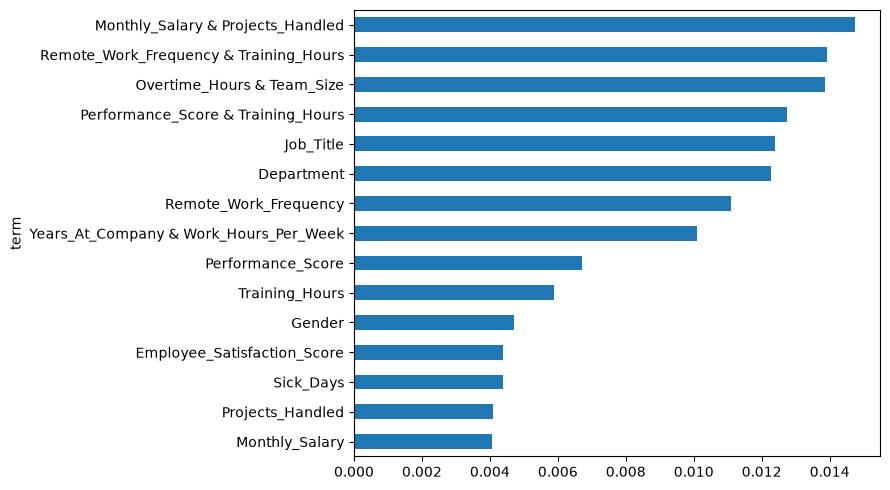

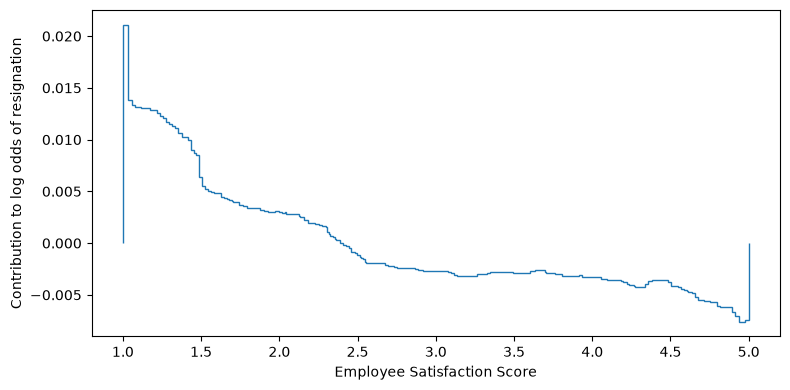

In [6]:
from src.models.ebm_experiments import fit_candidate
import yaml
contract = yaml.safe_load((PROJECT_ROOT / "configs/feature_contract.yaml").read_text())
features = contract["primary_model_features"]
categories = [f["name"] for f in contract["categorical_features"]]
selected_id = oof.loc[oof.cv_fold == 1, "selected_candidate"].iloc[0]
candidate = next(c for c in CANDIDATES if c["candidate_id"] == selected_id)
training = data.loc[data.cv_fold != 1]
explanation_model, _, _ = fit_candidate(training[features], training.Resigned, candidate, categories)
explanation = explanation_model.explain_global()
importance = pd.DataFrame({"term": explanation.data()["names"], "importance": explanation.data()["scores"]}).sort_values("importance", ascending=False)
display(importance.head(10))
importance.head(15).sort_values("importance").plot.barh(x="term", y="importance", legend=False, figsize=(9,5))
plt.tight_layout(); plt.savefig(output_dir / "term_importance.png", dpi=160); plt.show()
term_index = next(i for i,t in enumerate(explanation_model.term_features_) if len(t) == 1 and features[t[0]] == "Employee_Satisfaction_Score")
shape = explanation.data(term_index)
plt.figure(figsize=(8,4)); plt.stairs(shape["scores"], shape["names"])
plt.xlabel("Employee Satisfaction Score"); plt.ylabel("Contribution to log odds of resignation")
plt.tight_layout(); plt.savefig(output_dir / "satisfaction_shape.png", dpi=160); plt.show()
importance.to_csv(output_dir / "term_importances.csv", index=False)


## Demonstration guide and individual requirement evidence
1. Explain EBM's additive log-odds feature effects and optional pairwise interactions, and why it suits mixed HR predictors.
2. Show the six candidate settings and identify what changes between each pair and parameter setting.
3. Open `src/models/ebm_experiments.py`: demonstrate training-only scaler fitting, inner selection and outer prediction boundaries.
4. Show the comparison table, scaling differences, fold selections, PR curve and confusion matrix.
5. Explain why five folds are validation repetitions rather than different model varieties, and why high accuracy can coexist with zero recall.
6. State the actual conclusion and limitations. Explain that primary nested selection and fixed-variety comparison answer different questions.
7. Show your separate `IT25100429_Standardization.ipynb`; connect its z-score calculation to the scaler fitted inside these experiments.

Artifacts under `results/models/ebm/individual_IT25100429/` include candidate-level metrics, inner selections, OOF predictions, primary nested metrics, figures, a generated conclusion and runtime versions. The historical EBM notebook outputs remain in their original result directory.

Reference: [InterpretML ExplainableBoostingClassifier API](https://interpret.ml/docs/python/api/ExplainableBoostingClassifier.html).
